## Parte 1: o código original

MULTI-LAYER PERCEPTRON FROM SCRATCH
Adapted from original notebook from Vítor Gama Lemos

[kaggle-notebook](https://www.kaggle.com/code/vitorgamalemos/multilayer-perceptron-from-scratch)


In [1]:
import random
import seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

seaborn.set(style='whitegrid'); seaborn.set_context('talk')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from sklearn.datasets import load_iris
iris_data = load_iris()

In [2]:
print(iris_data['DESCR'])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

Number of samples: 150
Number of features: 4 



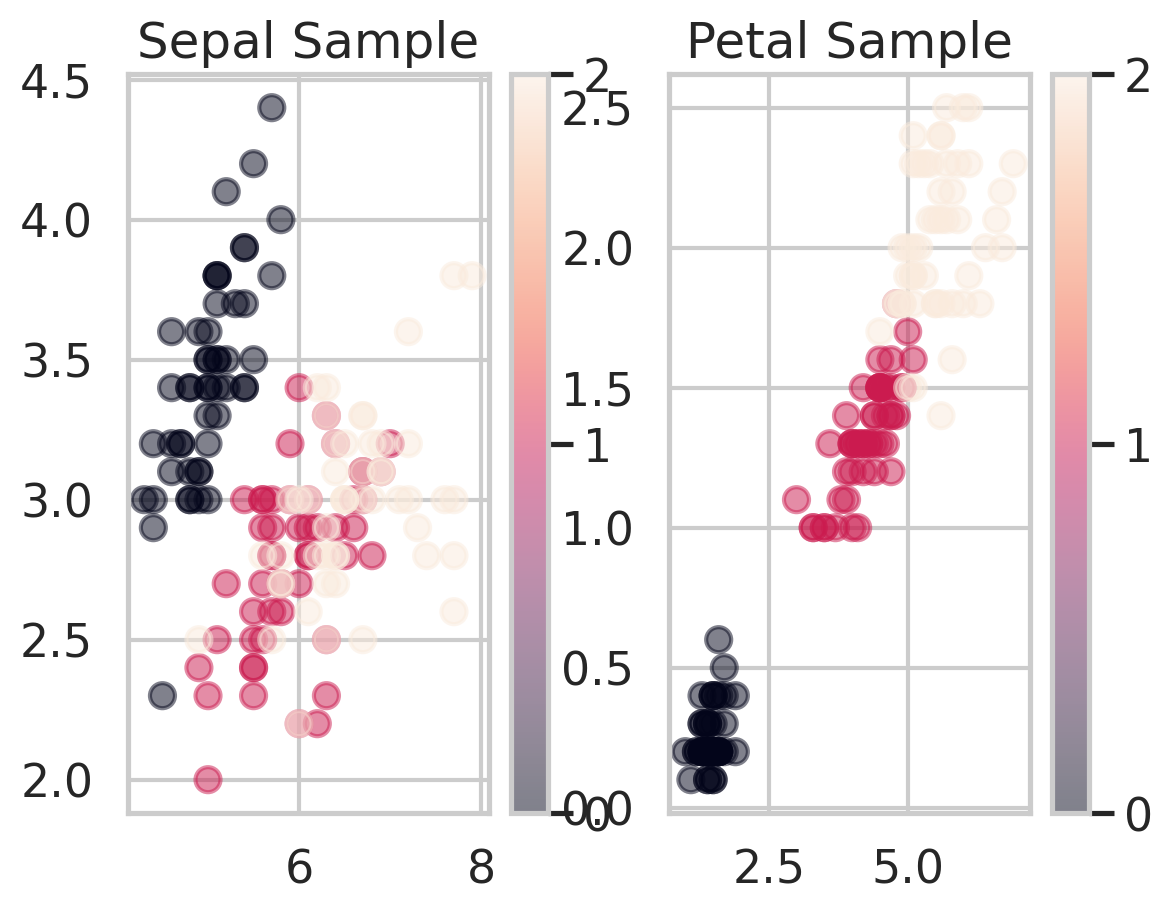

In [3]:
n_samples, n_features = iris_data.data.shape

print(f"Number of samples: {n_samples}")
print(f"Number of features: {n_features} \n")

plt.subplot(1, 2, 1)
scatter_plot = plt.scatter(iris_data.data[:,0], iris_data.data[:,1], alpha=0.5,
                           c=iris_data.target)
plt.colorbar(ticks=([0, 1, 2]))
plt.title('Sepal Sample');

plt.subplot(1, 2, 2)
scatter_plot_2 = plt.scatter(iris_data.data[:,2], iris_data.data[:,3], alpha=0.5,
                           c=iris_data.target)
plt.colorbar(ticks=([0, 1, 2]))
plt.title('Petal Sample');

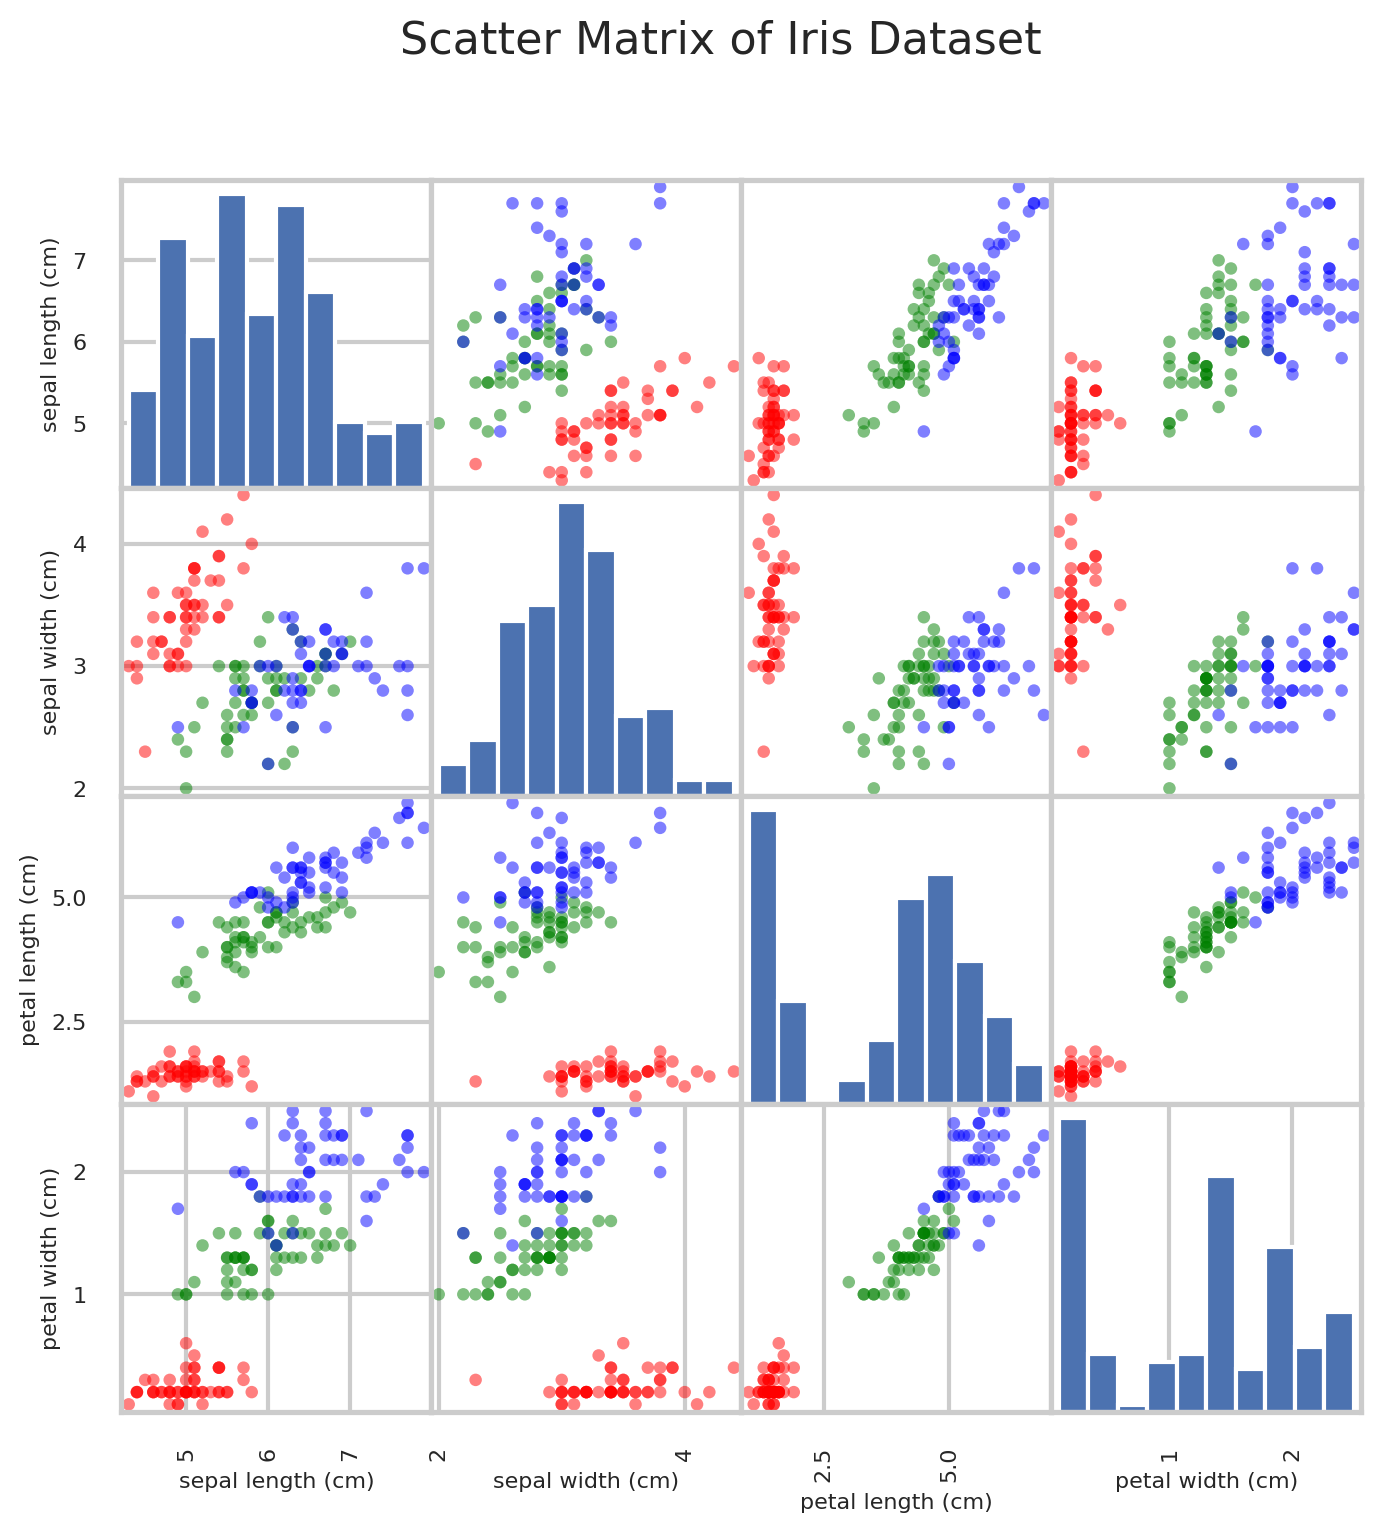

In [4]:
import pandas
from pandas.plotting import scatter_matrix


# Cria um DataFrame com os dados e os nomes das colunas
df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
df['target'] = iris_data.target

# Mapeia os números das classes para nomes legíveis
target_names = iris_data.target_names
df['target_name'] = df['target'].apply(lambda i: target_names[i])

# Escolhe uma paleta de cores
colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}
df['color'] = df['target_name'].map(colors)

# Gera o scatter_matrix
axes = scatter_matrix(df[iris_data.feature_names],
               figsize=(8, 8),
               diagonal='hist',
               color=df['color'],
               alpha=0.5)

# Reduz o tamanho da fonte dos rótulos dos eixos
for ax in axes.ravel():
    ax.set_xlabel(ax.get_xlabel(), fontsize=8)
    ax.set_ylabel(ax.get_ylabel(), fontsize=8)

plt.suptitle("Scatter Matrix of Iris Dataset", fontsize=16)
plt.show()

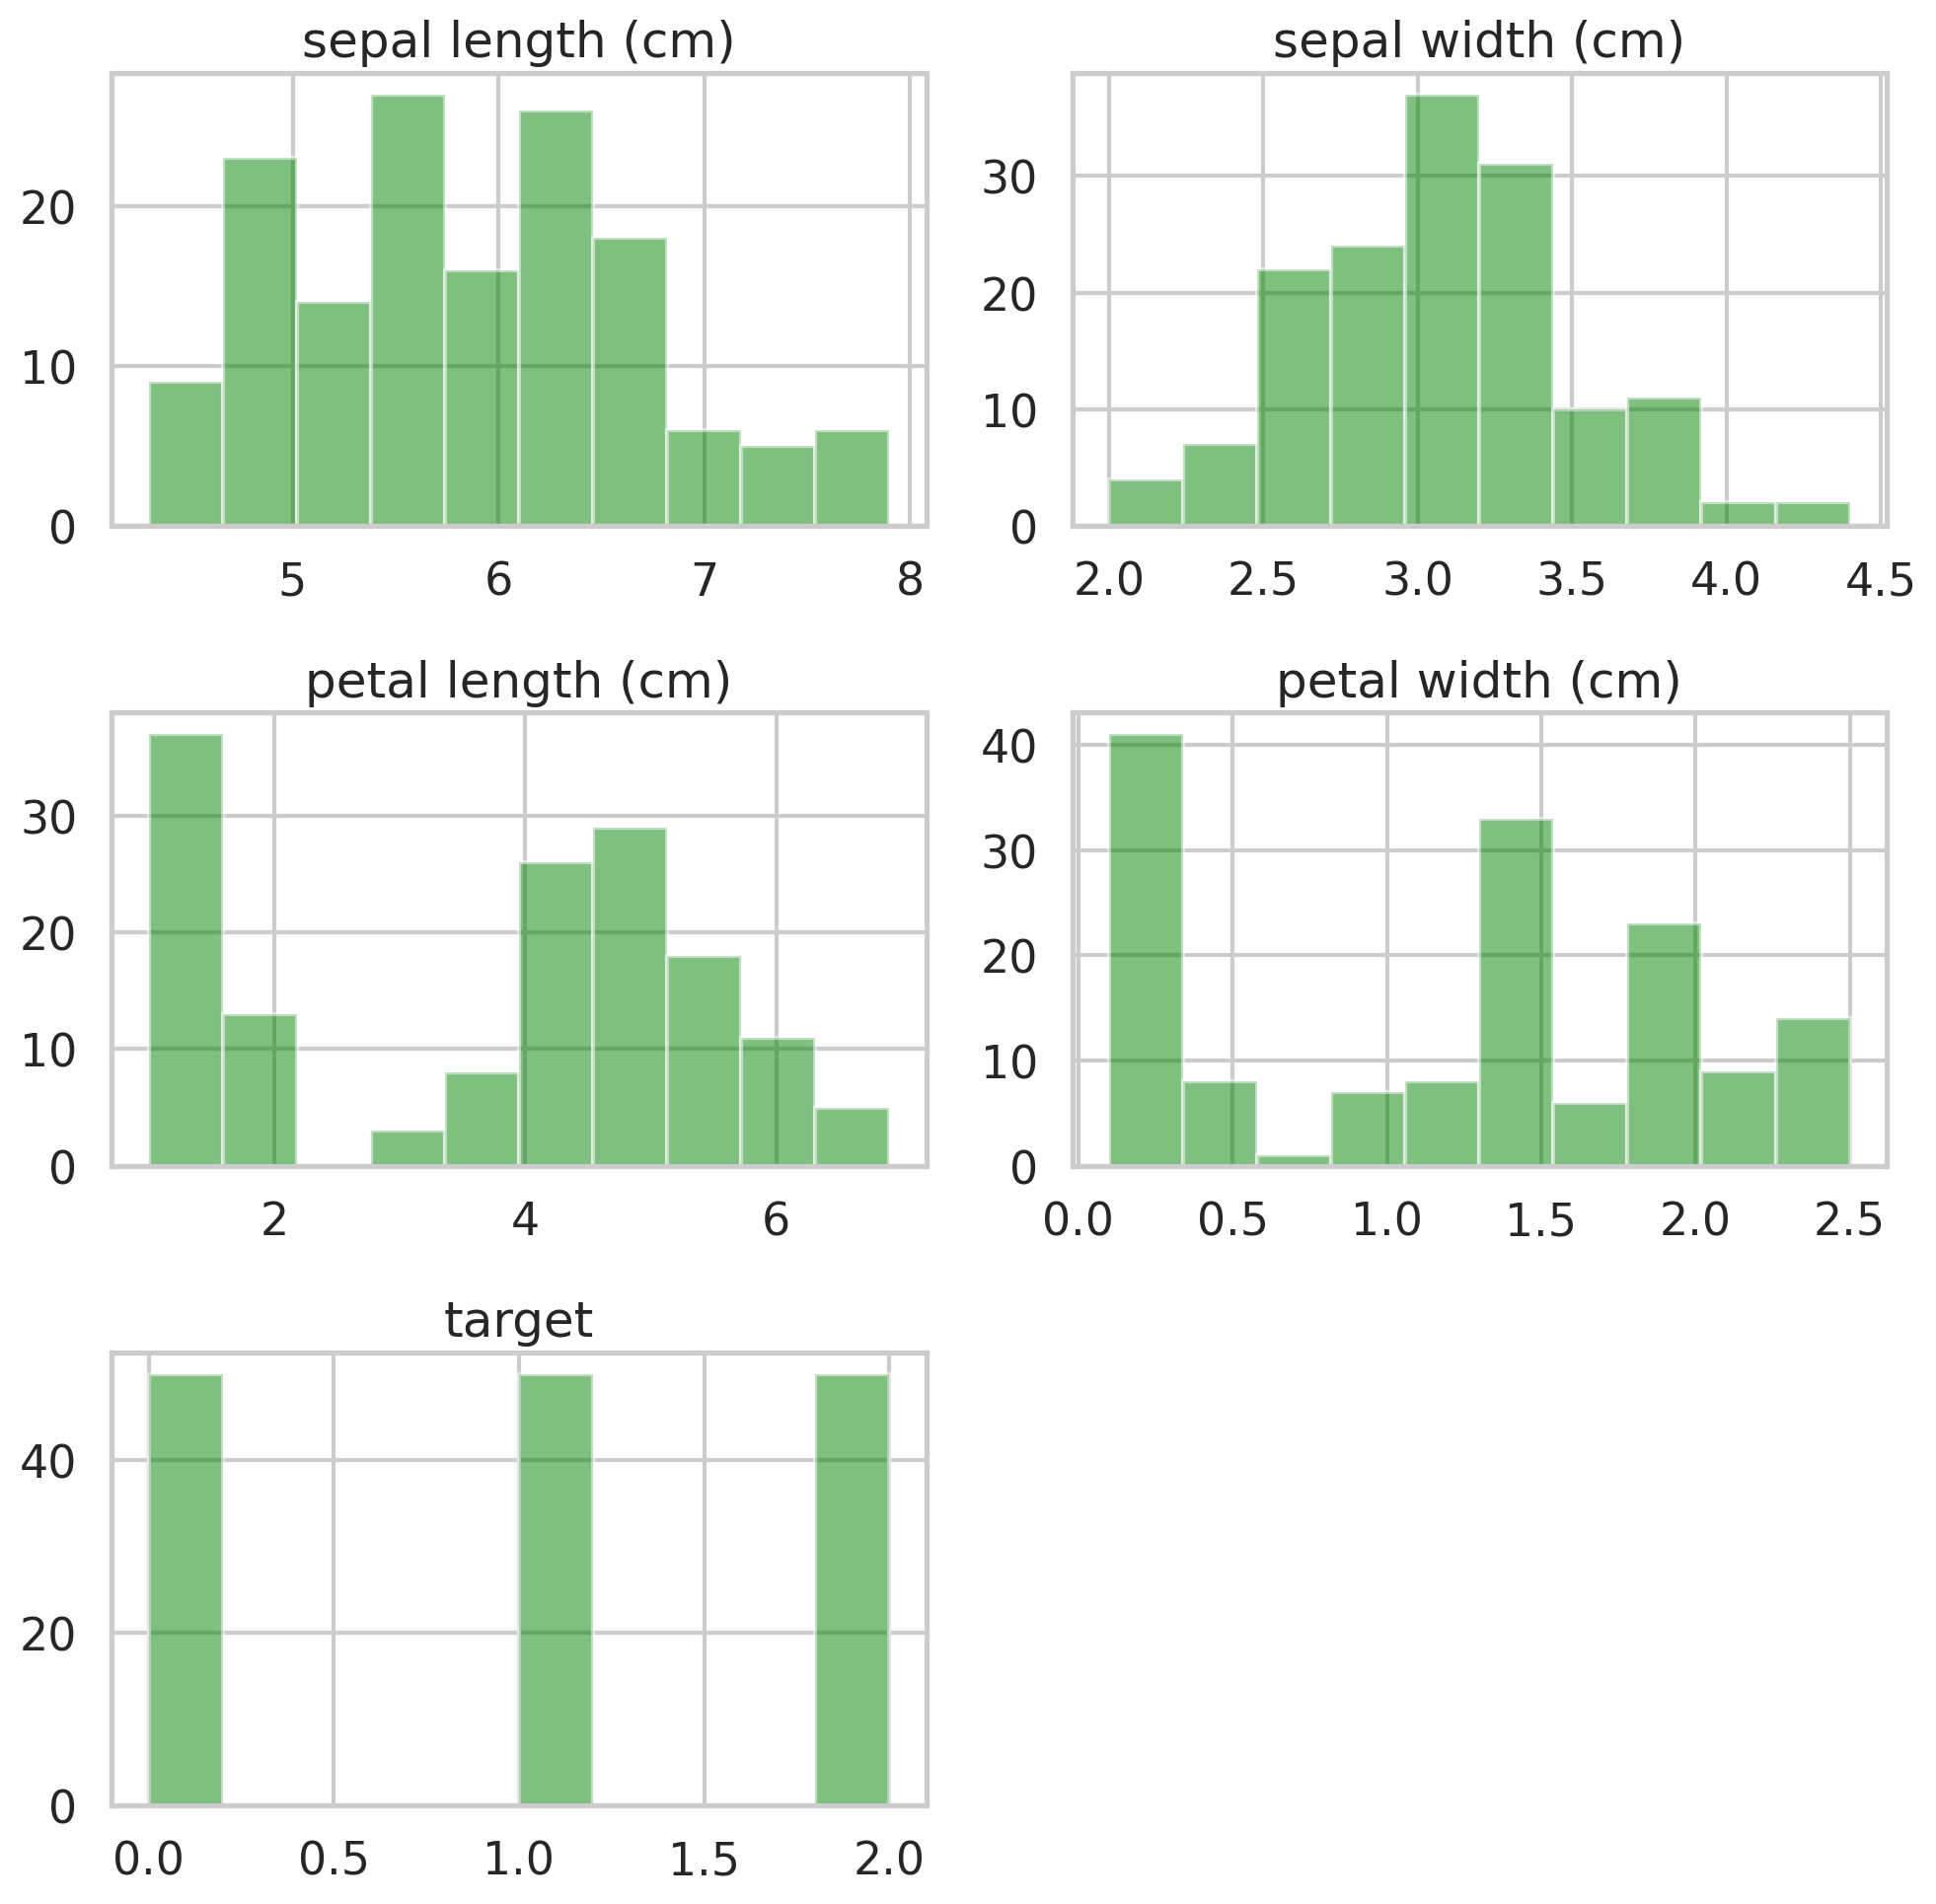

In [5]:
axes = df.hist(alpha=0.5, figsize=(10, 10), color='green')

plt.tight_layout()
plt.show()

In [6]:
import numpy as np
import random
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Load the Iris dataset
iris_data = load_iris()

# Join features and labels into a single array
iris_dataset = np.column_stack((iris_data.data, iris_data.target.T))  # shape (150, 5)

# Shuffle the dataset (optional: for reproducibility)
random.seed(123)
random.shuffle(iris_dataset)

# Split features (X) and labels (y)
X = np.array([i[:4] for i in iris_dataset])  # shape (150, 4)
y = np.array([i[4] for i in iris_dataset])   # shape (150,)

# Use train_test_split to divide into 80% train, 20% test
train_X, test_X, train_y, test_y = train_test_split(
    X, y,
    test_size=0.2,
    random_state=11,  # set for reproducibility
    stratify=y        # keep label proportions balanced
)

# Now you have train_X, train_y, test_X, test_y ready

print(test_y)

[0. 0. 0. 1. 1. 0. 1. 0. 1. 0. 0. 1. 0. 0. 1. 0. 1. 0. 0. 2. 0. 0. 1. 0.
 0. 1. 0. 0. 0. 0.]


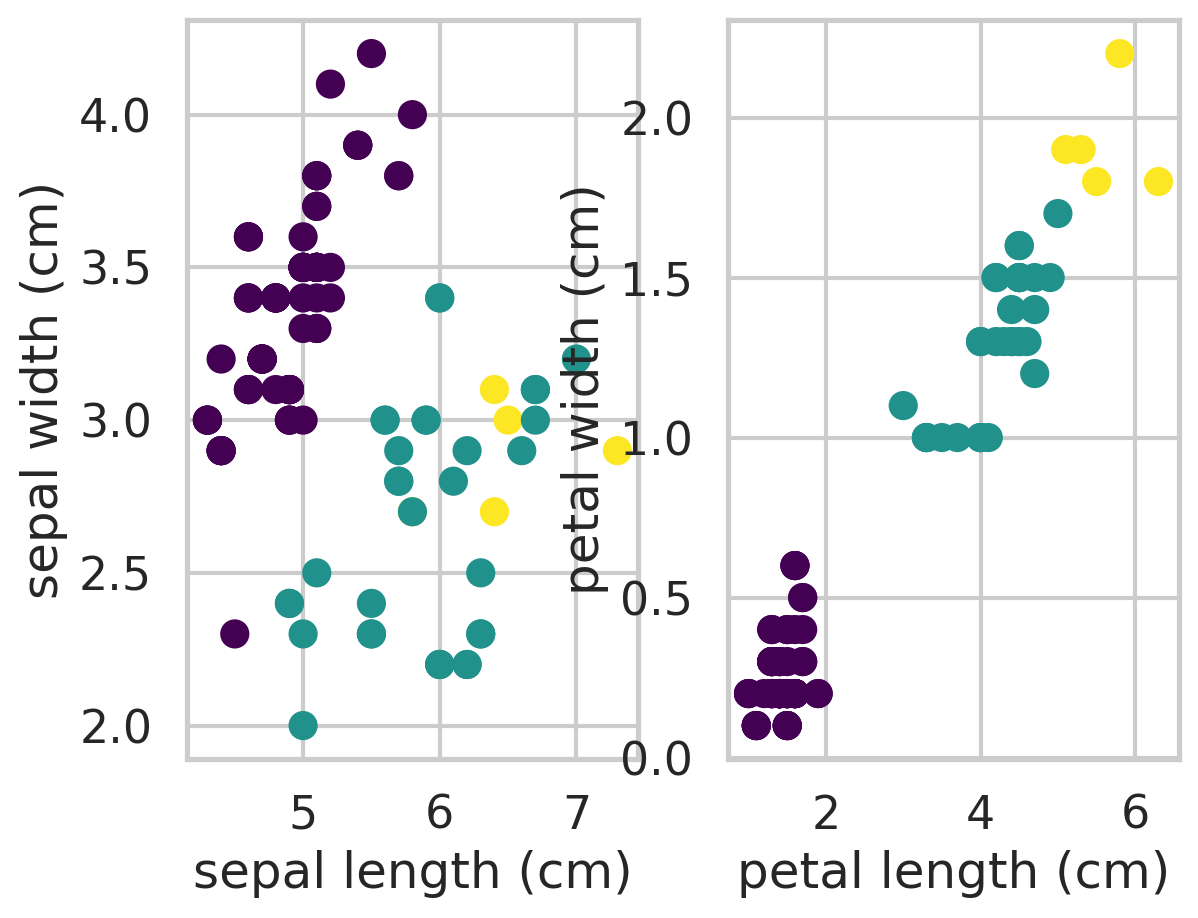

In [7]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Plot training Samples

plt.subplot(1, 2, 1)
plt.scatter(train_X[:,0],train_X[:,1],c=train_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[0])
plt.ylabel(iris_data.feature_names[1])

plt.subplot(1, 2, 2)
plt.scatter(train_X[:,2],train_X[:,3],c=train_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[2])
plt.ylabel(iris_data.feature_names[3]);

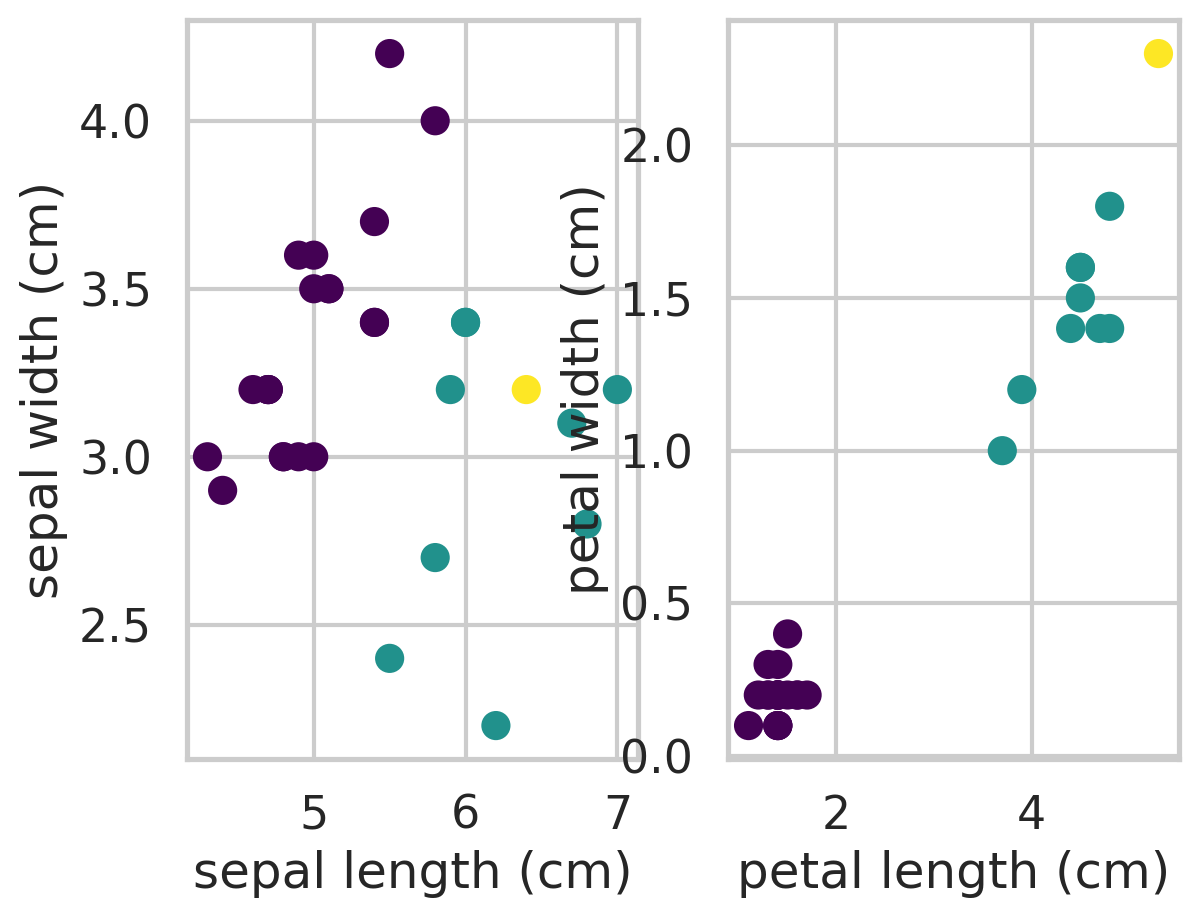

In [8]:
# Plot test samples
plt.subplot(1, 2, 1)
plt.scatter(test_X[:,0],test_X[:,1],c=test_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[0])
plt.ylabel(iris_data.feature_names[1])

plt.subplot(1, 2, 2)
plt.scatter(test_X[:,2],test_X[:,3],c=test_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[2])
plt.ylabel(iris_data.feature_names[3]);

In [9]:
# Implementation the Multilayer Perceptron in Python
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
import random
import numpy as np
import matplotlib.pyplot as plt

class MultiLayerPerceptron(BaseEstimator, ClassifierMixin):

    def __init__(self, params=None):
        # Store the params argument to satisfy BaseEstimator requirements
        self.params = params

        if (params == None):
            self.inputLayer = 4                        # Input Layer
            self.hiddenLayer = 5                       # Hidden Layer
            self.outputLayer = 3                       # Outpuy Layer
            self.learningRate = 0.005                  # Learning rate
            self.max_epochs = 600                      # Epochs
            self.iasHiddenValue = -1                   # Bias HiddenLayer
            self.BiasOutputValue = -1                  # Bias OutputLayer
            self.activation = self.ativacao['sigmoid'] # Activation function
            self.deriv = self.derivada['sigmoid']
        else:
            self.inputLayer = params['InputLayer']
            self.hiddenLayer = params['HiddenLayer']
            self.outputLayer = params['OutputLayer']
            self.learningRate = params['LearningRate']
            self.max_epochs = params['Epocas']
            self.BiasHiddenValue = params['BiasHiddenValue']
            self.BiasOutputValue = params['BiasOutputValue']
            self.activation = self.ativacao[params['ActivationFunction']]
            self.deriv = self.derivada[params['ActivationFunction']]

        # Starting Bias and Weights
        # assign ramdom values [-1 .. +1] in order to start with some weights
        # not so symmetric
        # Weight initialization: passing correct arguments to starting_weights
        self.WEIGHT_hidden = self.starting_weights(self.inputLayer, self.hiddenLayer)
        self.WEIGHT_output = self.starting_weights(self.hiddenLayer, self.outputLayer)

        self.BIAS_hidden = np.array([self.BiasHiddenValue for i in range(self.hiddenLayer)])
        self.BIAS_output = np.array([self.BiasOutputValue for i in range(self.outputLayer)]) # Corrected attribute name
        self.classes_number = 3

    pass

    # This function creates a 2D matrix of random values between -1 and +1
    # Shape: rows x columns
    def starting_weights(self, rows, columns):
        return [[2  * random.random() - 1 for _ in range(columns)] for _ in range(rows)]

    ativacao = {
         'sigmoid': (lambda x: 1/(1 + np.exp(-x))),
            'tanh': (lambda x: np.tanh(x)),
            'Relu': (lambda x: x*(x > 0)),
               }
    derivada = {
         'sigmoid': (lambda x: x*(1-x)),
            'tanh': (lambda x: 1-x**2),
            'Relu': (lambda x: 1 * (x>0))
               }

    # This calculates the error at the output layer and then propagates it
    # backward through the network to update the weights in each layer
    def Backpropagation_Algorithm(self, x):
        DELTA_output = []
        # Stage 1 - Error: OutputLayer (target - predicted)
        ERROR_output = self.output - self.OUTPUT_L2
        DELTA_output = ((-1)*(ERROR_output) * self.deriv(self.OUTPUT_L2))

        arrayStore = []
        # Stage 2 - Update weights OutputLayer and HiddenLayer
        for i in range(self.hiddenLayer):
            for j in range(self.outputLayer): # Corrected attribute name
                self.WEIGHT_output[i][j] -= (self.learningRate * (DELTA_output[j] * self.OUTPUT_L1[i]))
                self.BIAS_output[j] -= (self.learningRate * DELTA_output[j])

        # Stage 3 - Error: HiddenLayer
        delta_hidden = np.matmul(self.WEIGHT_output, DELTA_output)* self.deriv(self.OUTPUT_L1)

        # Stage 4 - Update weights HiddenLayer and InputLayer(x)
        for i in range(self.inputLayer):
            for j in range(self.hiddenLayer):
                self.WEIGHT_hidden[i][j] -= (self.learningRate * (delta_hidden[j] * x[i]))
                self.BIAS_hidden[j] -= (self.learningRate * delta_hidden[j])



    def show_err_graphic(self,v_erro,v_epoca):
        plt.figure(figsize=(9,4))
        plt.plot(v_epoca, v_erro, color="b", marker=11)
        plt.xlabel("Number of Epochs")
        plt.ylabel("Squared error (MSE) ");
        plt.title("Error Minimization")
        plt.show()


    def predict(self, X, y):
        'Returns the predictions for every element of X'
        my_predictions = []
        'Forward Propagation'
        forward = np.matmul(X,self.WEIGHT_hidden) + self.BIAS_hidden
        forward = np.matmul(forward, self.WEIGHT_output) + self.BIAS_output
        for i in forward:
            my_predictions.append(max(enumerate(i), key=lambda x:x[1])[0])

        array_score = []
        for i in range(len(my_predictions)):
            if my_predictions[i] == 0:
                array_score.append([i, 'Iris-setosa', my_predictions[i], y[i]])
            elif my_predictions[i] == 1:
                 array_score.append([i, 'Iris-versicolour', my_predictions[i], y[i]])
            elif my_predictions[i] == 2:
                 array_score.append([i, 'Iris-virginica', my_predictions[i], y[i]])

        dataframe = pd.DataFrame(array_score, columns=['_id', 'class', 'output', 'hoped_output'])
        return my_predictions, dataframe

    def fit(self, X, y):
        count_epoch = 1
        total_error = 0
        n = len(X);
        epoch_array = []
        error_array = []
        # Initialize lists to store specific weight values for plotting
        weight_over_epochs_W0_plot = []
        weight_over_epochs_W1_plot = []


        while(count_epoch <= self.max_epochs):
            for idx,inputs in enumerate(X):
                self.output = np.zeros(self.classes_number)
                'Stage 1 - (Forward Propagation)'
                self.OUTPUT_L1 = self.activation((np.dot(inputs, self.WEIGHT_hidden) + self.BIAS_hidden))
                self.OUTPUT_L2 = self.activation((np.dot(self.OUTPUT_L1, self.WEIGHT_output) + self.BIAS_output))
                'Stage 2 - One-Hot-Encoding'
                if(y[idx] == 0):
                    self.output = np.array([1,0,0]) #Class1 {1,0,0}
                elif(y[idx] == 1):
                    self.output = np.array([0,1,0]) #Class2 {0,1,0}
                elif(y[idx] == 2):
                    self.output = np.array([0,0,1]) #Class3 {0,0,1}

                square_error = 0
                for i in range(self.outputLayer):
                    erro = (self.output[i] - self.OUTPUT_L2[i])**2
                    square_error = (square_error + (0.05 * erro))
                    total_error = total_error + square_error

                'Backpropagation : Update Weights'
                self.Backpropagation_Algorithm(inputs)

            # The original code calculates total_error per batch, then divides by n (number of samples).
            # It's more standard to calculate the mean squared error per epoch by summing errors over
            # all samples in the epoch and then dividing by the number of output neurons.
            # Keeping the original logic for total_error calculation, but this is not
            # a standard MSE calculation.
            total_error = (total_error / n)
            if((count_epoch % 50 == 0)or(count_epoch == 1)):
                print("Epoch ", count_epoch, "- Total Error: ",total_error)
                error_array.append(total_error)
                epoch_array.append(count_epoch)
                # Append the specific weight values only when we are recording the epoch
                weight_over_epochs_W0_plot.append(self.WEIGHT_hidden[0][0])
                weight_over_epochs_W1_plot.append(self.WEIGHT_output[0][0])


            # Reset total_error for the next epoch
            total_error = 0

            count_epoch += 1
        self.show_err_graphic(error_array,epoch_array)

        # Plot the change of a *single* weight over the epochs that were recorded
        plt.figure(figsize=(8, 4))
        # Use the new lists which have the same length as epoch_array
        plt.plot(epoch_array, weight_over_epochs_W0_plot, label='Weight[0][0]')
        plt.title('Change of a Sample Weight (Input 0 to Hidden 0) over Epochs')
        plt.xlabel('Number of Epochs')
        plt.ylabel('Weight Value')
        plt.legend()
        plt.show()

        plt.figure(figsize=(8, 4))
        # Use the new lists which have the same length as epoch_array
        plt.plot(epoch_array, weight_over_epochs_W1_plot, label='Weight[0][0]')
        plt.title('Change of a Sample Weight (Hidden 0 to Output 0) over Epochs')
        plt.xlabel('Number of Epochs')
        plt.ylabel('Weight Value')
        plt.legend()
        plt.show()


        return self

Epoch  1 - Total Error:  0.06758981166881102


Epoch  50 - Total Error:  0.04024720417130557


Epoch  100 - Total Error:  0.02286486557652496


Epoch  150 - Total Error:  0.013276352862066243


Epoch  200 - Total Error:  0.009687618408255076


...

Epoch  2800 - Total Error:  0.005608864019851898


Epoch  2850 - Total Error:  0.0056060115886331545


Epoch  2900 - Total Error:  0.005603256875035709


Epoch  2950 - Total Error:  0.005600594865865163


Epoch  3000 - Total Error:  0.005598020889700072


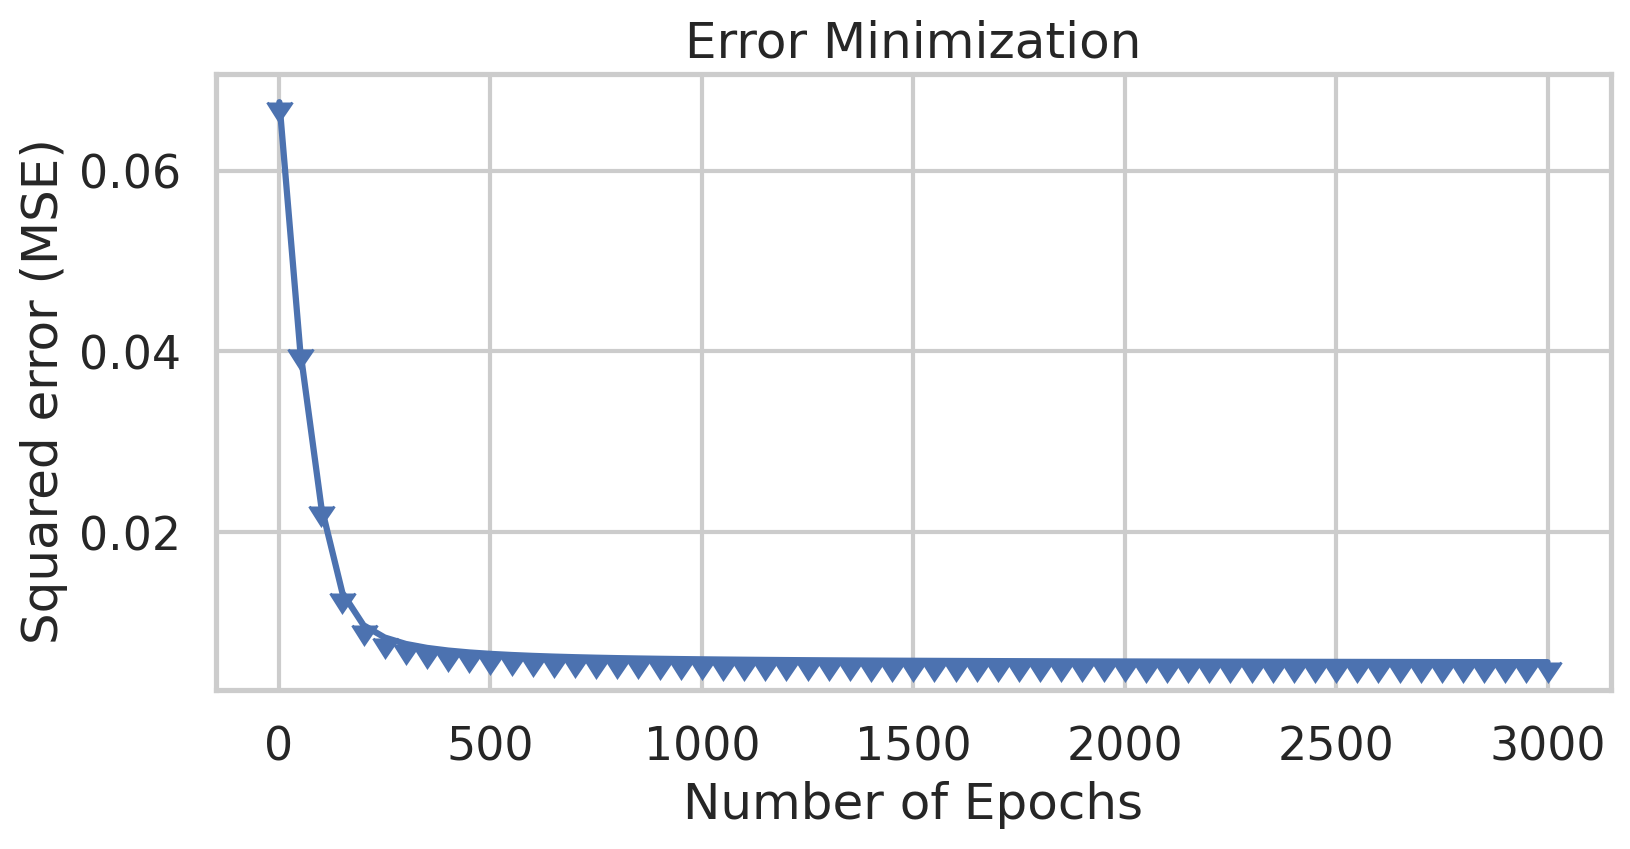

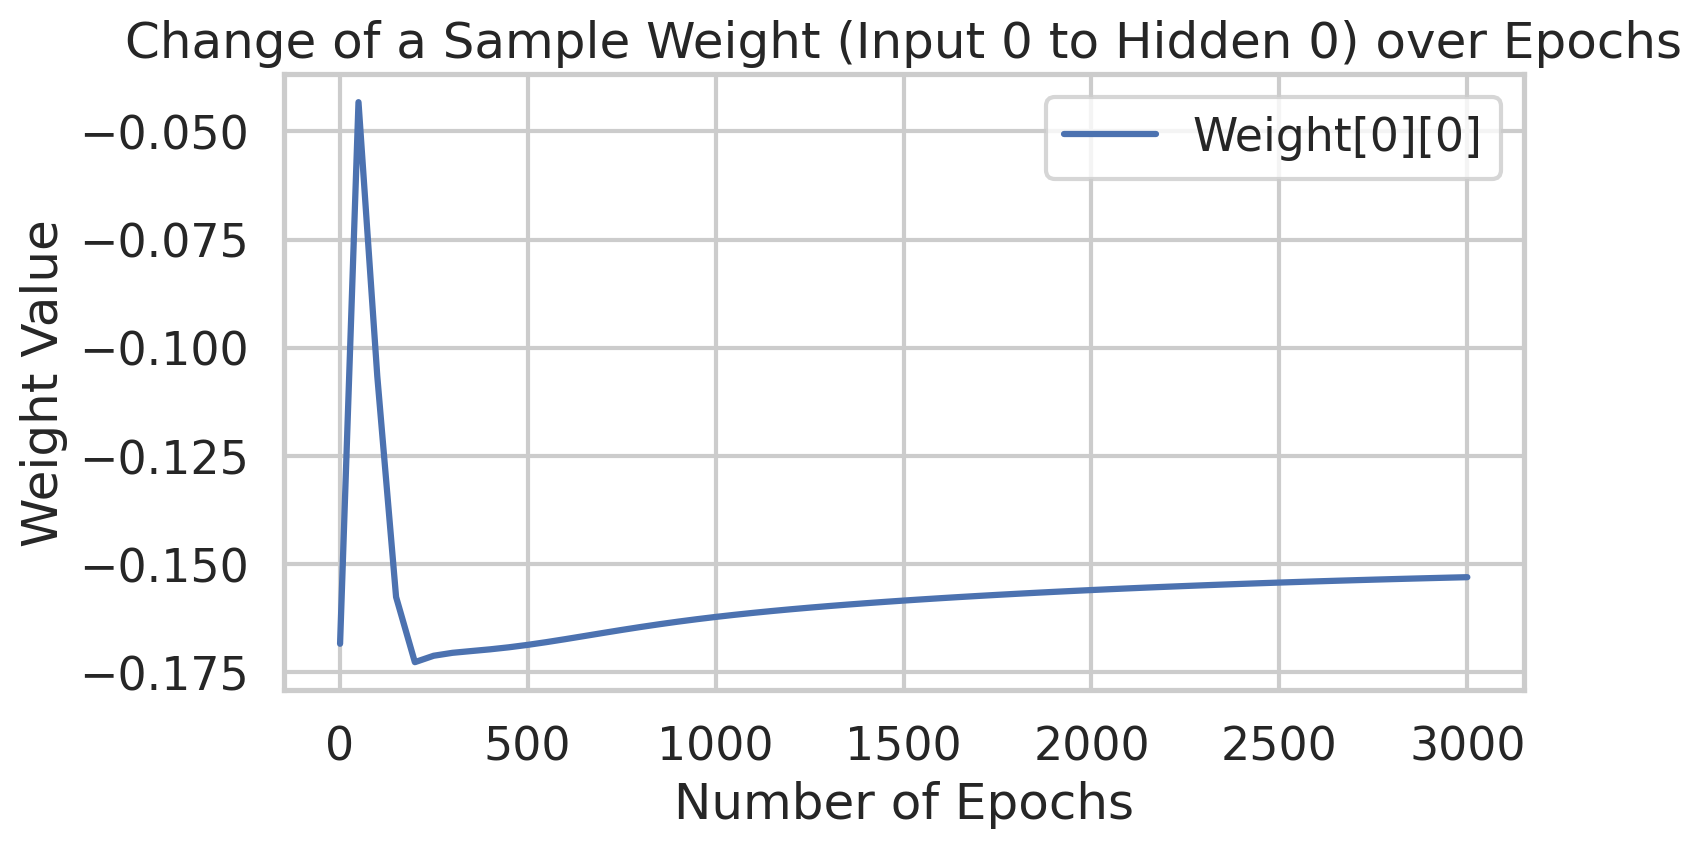

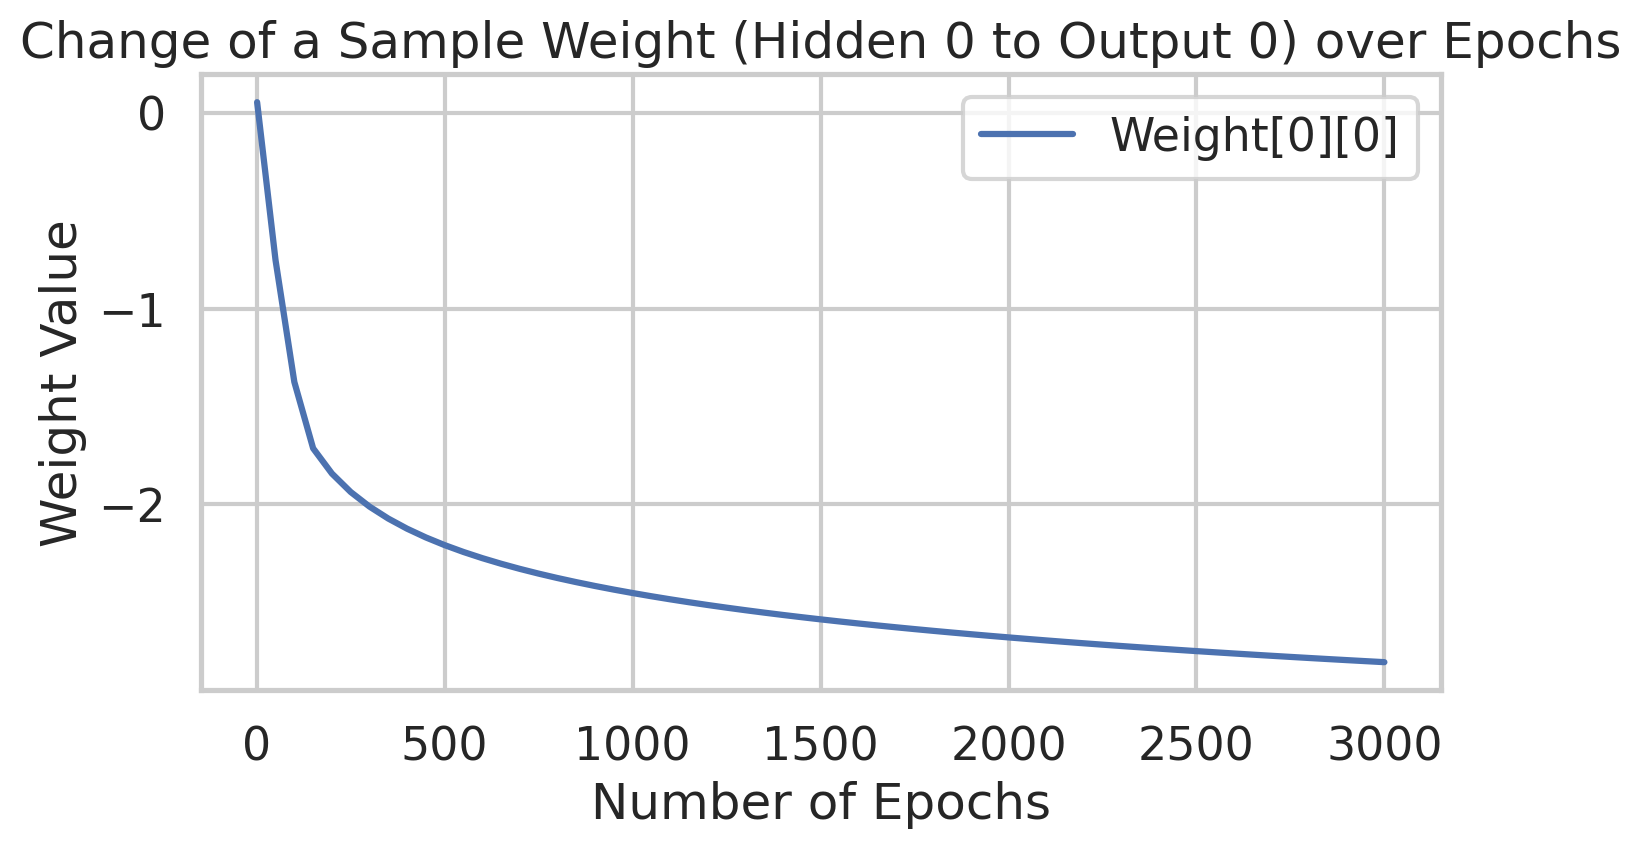

MultiLayerPerceptron(params={'ActivationFunction': 'sigmoid',
                             'BiasHiddenValue': -1, 'BiasOutputValue': -1,
                             'Epocas': 3000, 'HiddenLayer': 5, 'InputLayer': 4,
                             'LearningRate': 0.005, 'OutputLayer': 3})

In [10]:
dictionary = {'InputLayer':4, 'HiddenLayer':5, 'OutputLayer':3,
              'Epocas':3000, 'LearningRate':0.005,'BiasHiddenValue':-1,
              'BiasOutputValue':-1, 'ActivationFunction':'sigmoid'}

Perceptron = MultiLayerPerceptron(dictionary)
Perceptron.fit(train_X,train_y)

In [11]:
prev, dataframe = Perceptron.predict(test_X, test_y)
hits = n_set = n_vers = n_virg = 0
score_set = score_vers = score_virg = 0
for j in range(len(test_y)):
    if(test_y[j] == 0): n_set += 1
    elif(test_y[j] == 1): n_vers += 1
    elif(test_y[j] == 2): n_virg += 1

for i in range(len(test_y)):
    if test_y[i] == prev[i]:
        hits += 1
    if test_y[i] == prev[i] and test_y[i] == 0:
        score_set += 1
    elif test_y[i] == prev[i] and test_y[i] == 1:
        score_vers += 1
    elif test_y[i] == prev[i] and test_y[i] == 2:
        score_virg += 1

hits = (hits / len(test_y)) * 100
faults = 100 - hits

print("Porcents :","%.2f"%(hits),"% hits","and","%.2f"%(faults),"% faults")
print("Total samples of test",len(test_y))
print("*Iris-Setosa:",n_set,"samples", score_set, "hits")
print("*Iris-Versicolour:",n_vers,"samples", score_vers, "hits")
print("*Iris-Virginica:",n_virg,"samples", score_virg, "hits")

Porcents : 96.67 % hits and 3.33 % faults
Total samples of test 30
*Iris-Setosa: 20 samples 20 hits
*Iris-Versicolour: 9 samples 9 hits
*Iris-Virginica: 1 samples 0 hits


In [12]:
dataframe

,_id,class,output,hoped_output
0,0,Iris-setosa,0,0.0
1,1,Iris-setosa,0,0.0
2,2,Iris-setosa,0,0.0
3,3,Iris-versicolour,1,1.0
4,4,Iris-versicolour,1,1.0
5,5,Iris-setosa,0,0.0
6,6,Iris-versicolour,1,1.0
7,7,Iris-setosa,0,0.0
8,8,Iris-versicolour,1,1.0
9,9,Iris-setosa,0,0.0


- Acurracy Iris-Setosa: 100.00 %
- Acurracy Iris-Versicolour: 100.00 %
- Acurracy Iris-Virginica: 0.00 %


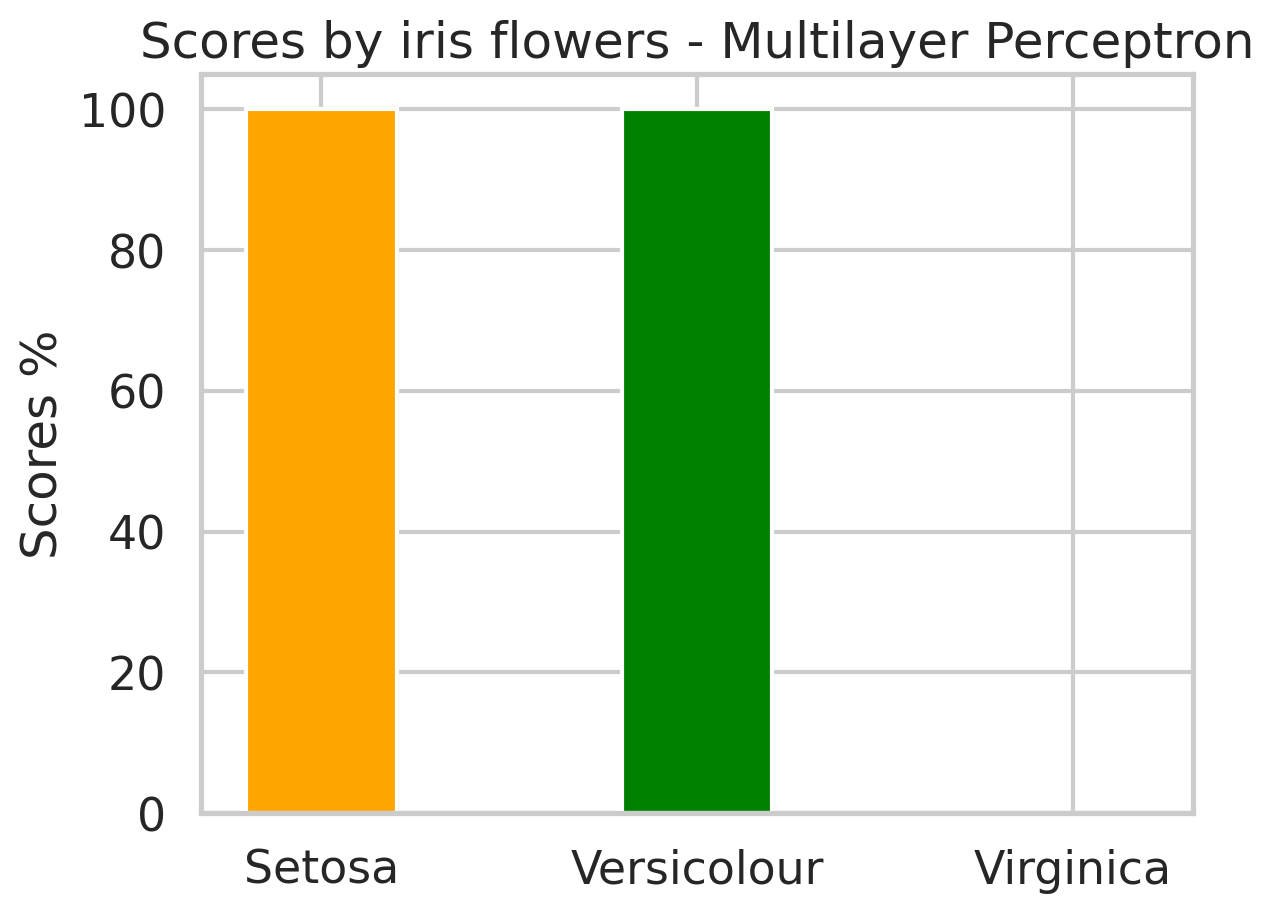

In [13]:
acc_set = (score_set/n_set)*100
acc_vers = (score_vers/n_vers)*100
acc_virg = (score_virg/n_virg)*100
print("- Acurracy Iris-Setosa:","%.2f"%acc_set, "%")
print("- Acurracy Iris-Versicolour:","%.2f"%acc_vers, "%")
print("- Acurracy Iris-Virginica:","%.2f"%acc_virg, "%")
names = ["Setosa","Versicolour","Virginica"]
x1 = [2.0,4.0,6.0]
fig, ax = plt.subplots()
r1 = plt.bar(x1[0], acc_set,color='orange',label='Iris-Setosa')
r2 = plt.bar(x1[1], acc_vers,color='green',label='Iris-Versicolour')
r3 = plt.bar(x1[2], acc_virg,color='purple',label='Iris-Virginica')
plt.ylabel('Scores %')
plt.xticks(x1, names);plt.title('Scores by iris flowers - Multilayer Perceptron')
plt.show()

## Parte 2: investigando o resultado
Antes de confiar nos 96,7%, vamos olhar os dados que entraram na rede.

In [14]:
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

sns.set_theme(style="whitegrid", context="notebook")

In [15]:
pd.Series(y).value_counts()

0.0    102
1.0     42
2.0      6
Name: count, dtype: int64

Era pra ser 50 de cada espécie, mas tem 102 setosa e só 6 virginica. A única coisa que mexeu nos dados antes disso foi o `random.shuffle`, então comparamos antes e depois:

In [16]:
antes = np.column_stack((iris_data.data, iris_data.target))
print("Linhas diferentes antes do shuffle: ", len(np.unique(antes, axis=0)))
print("Linhas diferentes depois do shuffle:", len(np.unique(iris_dataset, axis=0)))

Linhas diferentes antes do shuffle:  149
Linhas diferentes depois do shuffle: 74


O shuffle está duplicando linhas (o Iris já tem 1 flor repetida, mas depois do shuffle sobram só 74 diferentes). O `random.shuffle` é do Python e não funciona direito com array do numpy: na hora de trocar duas linhas, uma é copiada por cima da outra.

E o teste?

In [17]:
print(pd.Series(test_y).value_counts())

treino_set = set(map(tuple, train_X))
repetidas = sum(tuple(linha) in treino_set for linha in test_X)
print("Flores do teste que também estão no treino:", repetidas, "de", len(test_X))

0.0    20
1.0     9
2.0     1
Name: count, dtype: int64
Flores do teste que também estão no treino: 18 de 30


Só 1 virginica no teste, e 18 das 30 flores a rede já tinha visto no treino. Então os 96,7% não querem dizer muita coisa.

**Correção:** tirar o `random.shuffle` e deixar o `train_test_split` embaralhar.

### Os bias
Outra coisa pra conferir é se a rede aprendeu tudo que devia. Imprimindo os pesos e os bias depois do treino:

In [18]:
print("Pesos entrada -> oculta:\n", np.round(Perceptron.WEIGHT_hidden, 2))
print("Bias oculta:", Perceptron.BIAS_hidden)
print("Bias saída: ", Perceptron.BIAS_output)

Pesos entrada -> oculta:
 [[-0.15 -0.96  1.12 -0.96  0.51]
 [-1.66 -0.6  -0.11  0.11  1.11]
 [ 2.12  2.46  0.73 -0.26 -2.04]
 [ 1.45  1.45 -0.39  0.68 -0.94]]
Bias oculta: [0 0 0 0 0]
Bias saída:  [0 0 0]


Os pesos mudaram, mas os bias estão todos em 0 (começaram em -1) e sem casa decimal. Eles foram criados com `np.array([-1 for i in range(n)])`, que é um array de inteiros:

In [19]:
Perceptron.BIAS_hidden.dtype

dtype('int64')

Então toda atualização é arredondada pra inteiro e o bias não aprende.

**Correção:** criar o bias como float.

### Testando nas 150 flores
Como o teste estava contaminado, rodamos o `predict` nas 150 flores originais:

In [20]:
prev_todas, _ = Perceptron.predict(iris_data.data, iris_data.target)
print("Acurácia nas 150 flores:", np.mean(np.array(prev_todas) == iris_data.target).round(3))
print(pd.Series(prev_todas).value_counts())

Acurácia nas 150 flores: 0.667
1    100
0     50
Name: count, dtype: int64


Bem pior que os 96,7%, e a rede nunca responde virginica (no treino tinha só 6). Olhando o que o `predict` calcula pra primeira flor, comparado com a conta que o `fit` faz no treino:

In [21]:
x = iris_data.data[:1]
saida_predict = np.matmul(np.matmul(x, Perceptron.WEIGHT_hidden) + Perceptron.BIAS_hidden,
                          Perceptron.WEIGHT_output) + Perceptron.BIAS_output
h = Perceptron.activation(np.dot(x, Perceptron.WEIGHT_hidden) + Perceptron.BIAS_hidden)
saida_fit = Perceptron.activation(np.dot(h, Perceptron.WEIGHT_output) + Perceptron.BIAS_output)

print("predict:", saida_predict.round(2))
print("fit:    ", saida_fit.round(2))

predict: [[ 37.97 -34.67 -23.72]]
fit:     [[0.98 0.02 0.01]]


A saída do `predict` nem fica entre 0 e 1: ele não aplica a sigmoid, então a rede que prevê não é a mesma que foi treinada.

**Correção:** usar no `predict` a mesma conta do `fit`.

### Outras coisas que achamos lendo o código
- `self.iasHiddenValue` (falta o B): criar a rede sem parâmetros dá erro.
- O bias é atualizado dentro do laço dos pesos, então várias vezes por amostra.
- O erro do gráfico não é o MSE, é uma soma acumulada.

In [22]:
# o construtor sem parâmetros
try:
    MultiLayerPerceptron()
except AttributeError as e:
    print("AttributeError:", e)

AttributeError: 'MultiLayerPerceptron' object has no attribute 'BiasHiddenValue'


## Parte 3: versão corrigida
Mantivemos a mesma ideia (1 camada oculta, saída sigmoid, erro quadrático, atualização amostra por amostra), só corrigindo os bugs e deixando mais curta com numpy.

Ela também guarda o erro e a acurácia de treino e de teste a cada época, pra gente analisar convergência e overfitting.

In [23]:
ativacoes = {
    "sigmoid": (lambda x: 1 / (1 + np.exp(-x)), lambda s: s * (1 - s)),
    "tanh":    (lambda x: np.tanh(x),           lambda s: 1 - s ** 2),
    "relu":    (lambda x: np.maximum(0, x),     lambda s: (s > 0) * 1.0),
}
sigmoid = ativacoes["sigmoid"][0]


class MLP:
    def __init__(self, n_entrada=4, n_oculta=5, n_saida=3, taxa=0.01, ativacao="sigmoid", seed=0):
        self.rng = np.random.default_rng(seed)
        self.W1 = self.rng.uniform(-1, 1, (n_entrada, n_oculta))
        self.b1 = np.zeros(n_oculta)
        self.W2 = self.rng.uniform(-1, 1, (n_oculta, n_saida))
        self.b2 = np.zeros(n_saida)
        self.taxa = taxa
        self.f, self.df = ativacoes[ativacao]
        self.n_saida = n_saida

    def forward(self, X):
        self.h = self.f(X @ self.W1 + self.b1)
        self.saida = sigmoid(self.h @ self.W2 + self.b2)
        return self.saida

    def backprop(self, x, alvo):
        saida = self.forward(x)
        # primeiro calcula os dois deltas...
        delta_saida = (saida - alvo) * saida * (1 - saida)
        delta_oculta = (self.W2 @ delta_saida) * self.df(self.h)
        # ...depois atualiza os pesos
        self.W2 -= self.taxa * np.outer(self.h, delta_saida)
        self.b2 -= self.taxa * delta_saida
        self.W1 -= self.taxa * np.outer(x, delta_oculta)
        self.b1 -= self.taxa * delta_oculta

    def one_hot(self, y):
        return np.eye(self.n_saida)[y.astype(int)]

    def erro(self, X, y):
        return np.mean((self.forward(X) - self.one_hot(y)) ** 2)

    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

    def fit(self, X, y, epocas=500, X_teste=None, y_teste=None):
        self.historico = []
        alvos = self.one_hot(y)
        for epoca in range(epocas):
            for i in self.rng.permutation(len(X)):  # embaralha a cada época
                self.backprop(X[i], alvos[i])
            linha = {"epoca": epoca + 1,
                     "erro_treino": self.erro(X, y),
                     "acc_treino": np.mean(self.predict(X) == y)}
            if X_teste is not None:
                linha["erro_teste"] = self.erro(X_teste, y_teste)
                linha["acc_teste"] = np.mean(self.predict(X_teste) == y_teste)
            self.historico.append(linha)
        self.historico = pd.DataFrame(self.historico)
        return self

### Dados separados direito
Agora a separação 80/20 é feita direto pelo `train_test_split` (que embaralha sozinho), com `stratify` pra ter 10 de cada classe no teste.

Também padronizamos as entradas (média 0, desvio 1). O `StandardScaler` aprende a média e o desvio **só no treino** e aplica no teste.

In [24]:
X = iris_data.data
y = iris_data.target
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=11, stratify=y)
print("Classes no teste:", np.bincount(y_teste))

scaler = StandardScaler().fit(X_treino)
X_treino_n = scaler.transform(X_treino)
X_teste_n = scaler.transform(X_teste)

Classes no teste: [10 10 10]


In [25]:
def plota_historico(modelo, titulo=""):
    hist = modelo.historico
    plt.figure(figsize=(14, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist["epoca"], hist["erro_treino"], label="treino")
    plt.plot(hist["epoca"], hist["erro_teste"], label="teste")
    plt.xlabel("Época")
    plt.ylabel("Erro quadrático médio")
    plt.title("Erro " + titulo)
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(hist["epoca"], hist["acc_treino"], label="treino")
    plt.plot(hist["epoca"], hist["acc_teste"], label="teste")
    plt.xlabel("Época")
    plt.ylabel("Acurácia")
    plt.title("Acurácia " + titulo)
    plt.legend()
    plt.show()

Acurácia treino: 0.975 | teste: 1.000


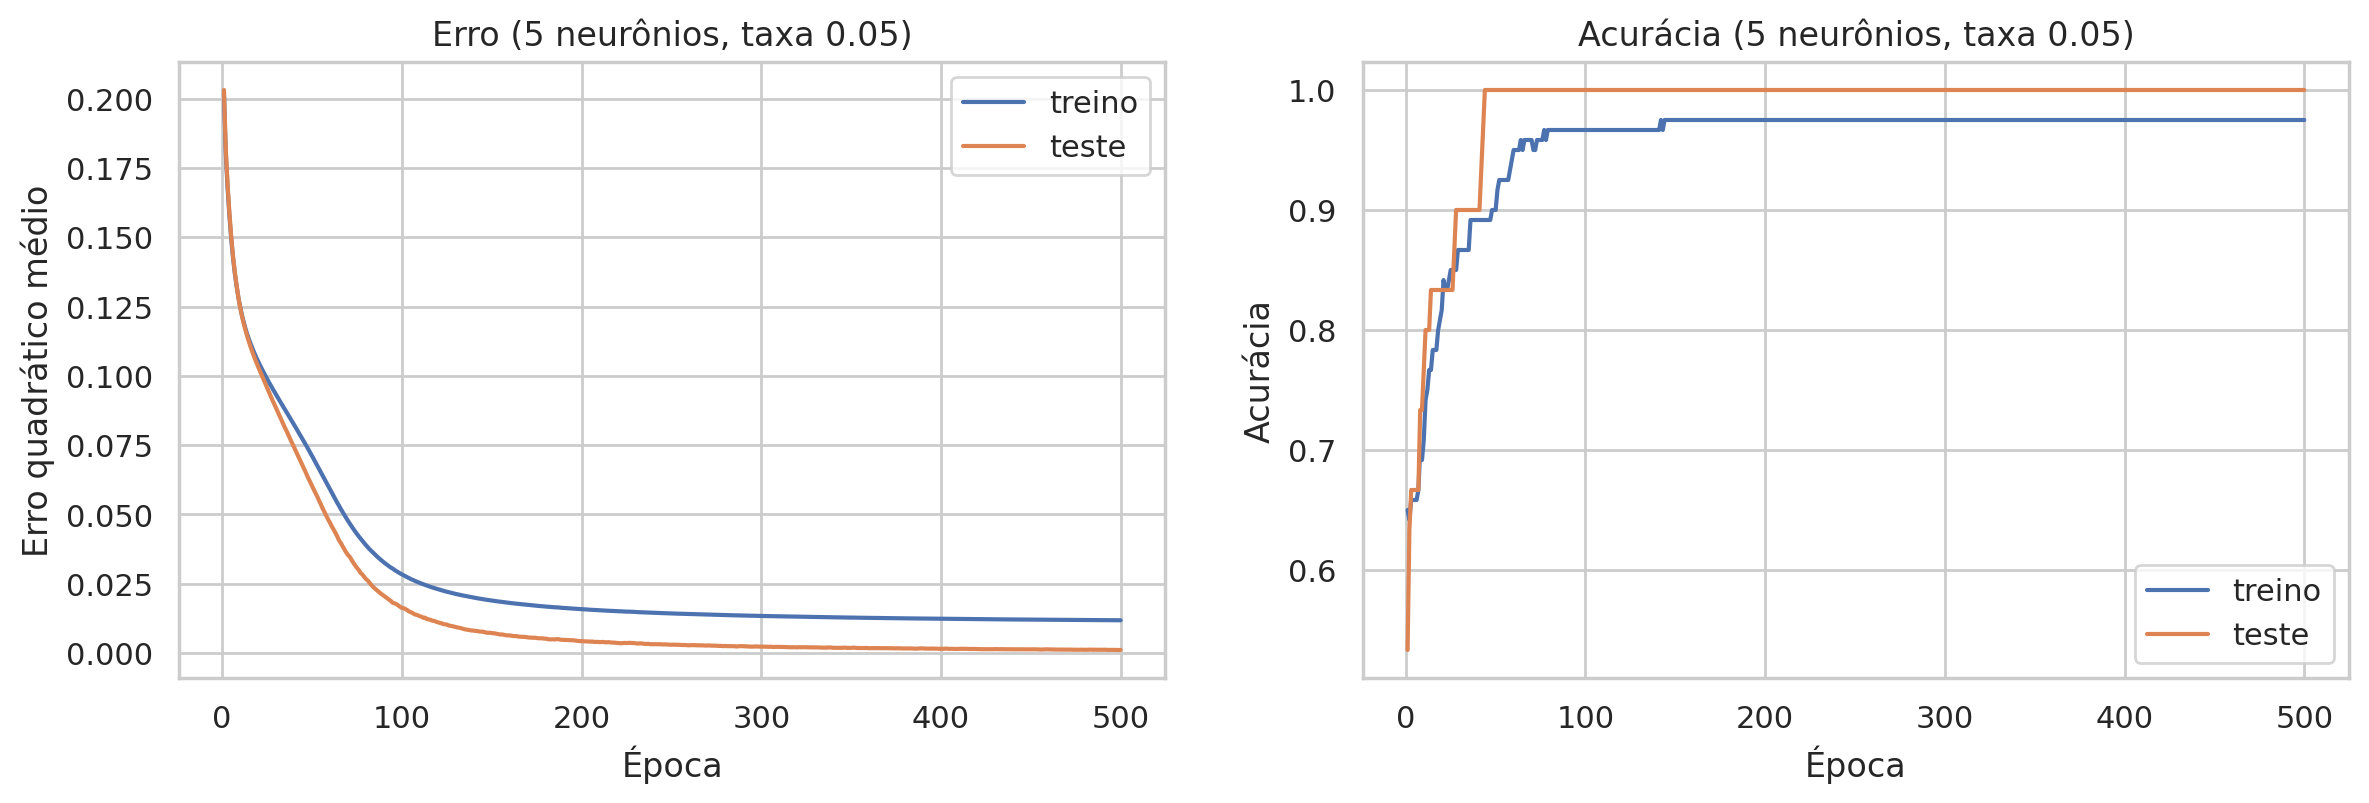

In [26]:
modelo = MLP(n_oculta=5, taxa=0.05, seed=0)
modelo.fit(X_treino_n, y_treino, epocas=500, X_teste=X_teste_n, y_teste=y_teste)
print("Acurácia treino: %.3f | teste: %.3f" % (modelo.historico["acc_treino"].iloc[-1], modelo.historico["acc_teste"].iloc[-1]))
plota_historico(modelo, "(5 neurônios, taxa 0.05)")

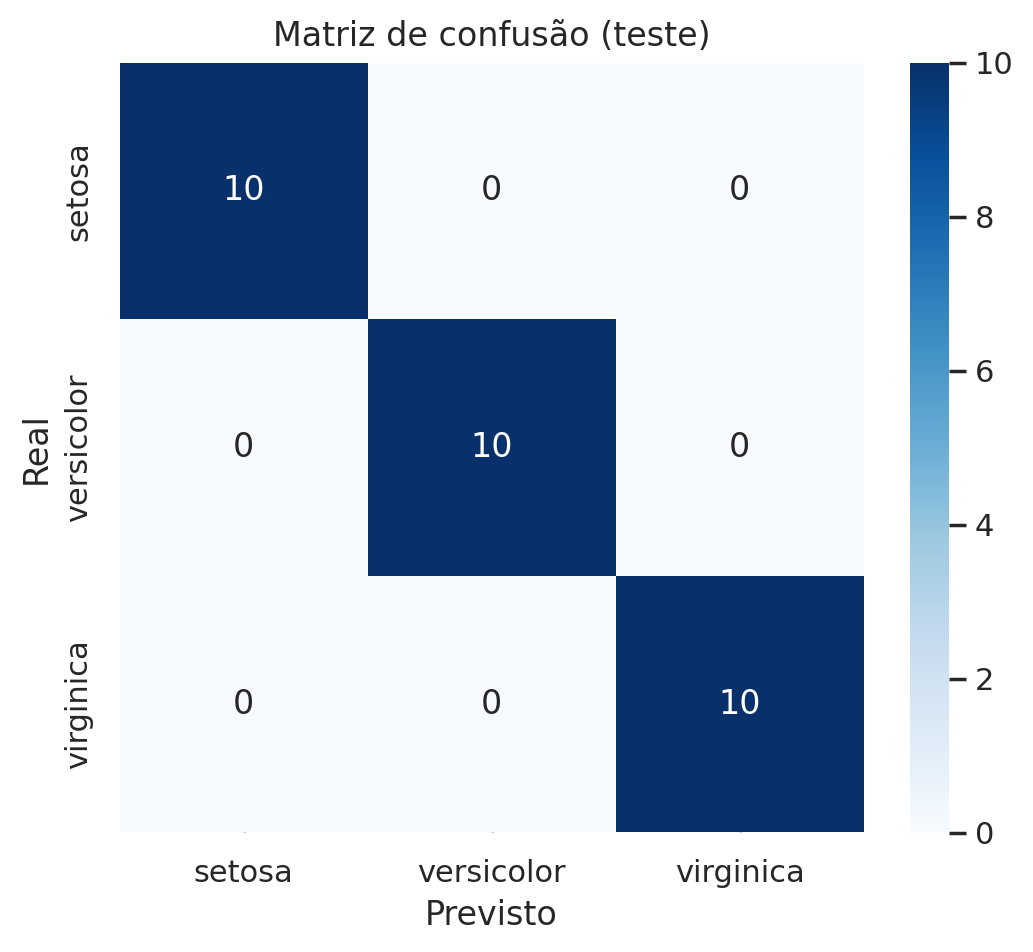

In [27]:
matriz = confusion_matrix(y_teste, modelo.predict(X_teste_n))
plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, cmap="Blues", xticklabels=iris_data.target_names, yticklabels=iris_data.target_names)
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de confusão (teste)")
plt.show()

## Parte 4: experimentos

### Normalizar ou não?
Sem normalizar, as entradas vão de ~0.1 a ~8. Com sigmoid, valores grandes saturam (derivada perto de 0) e a rede aprende mais devagar.

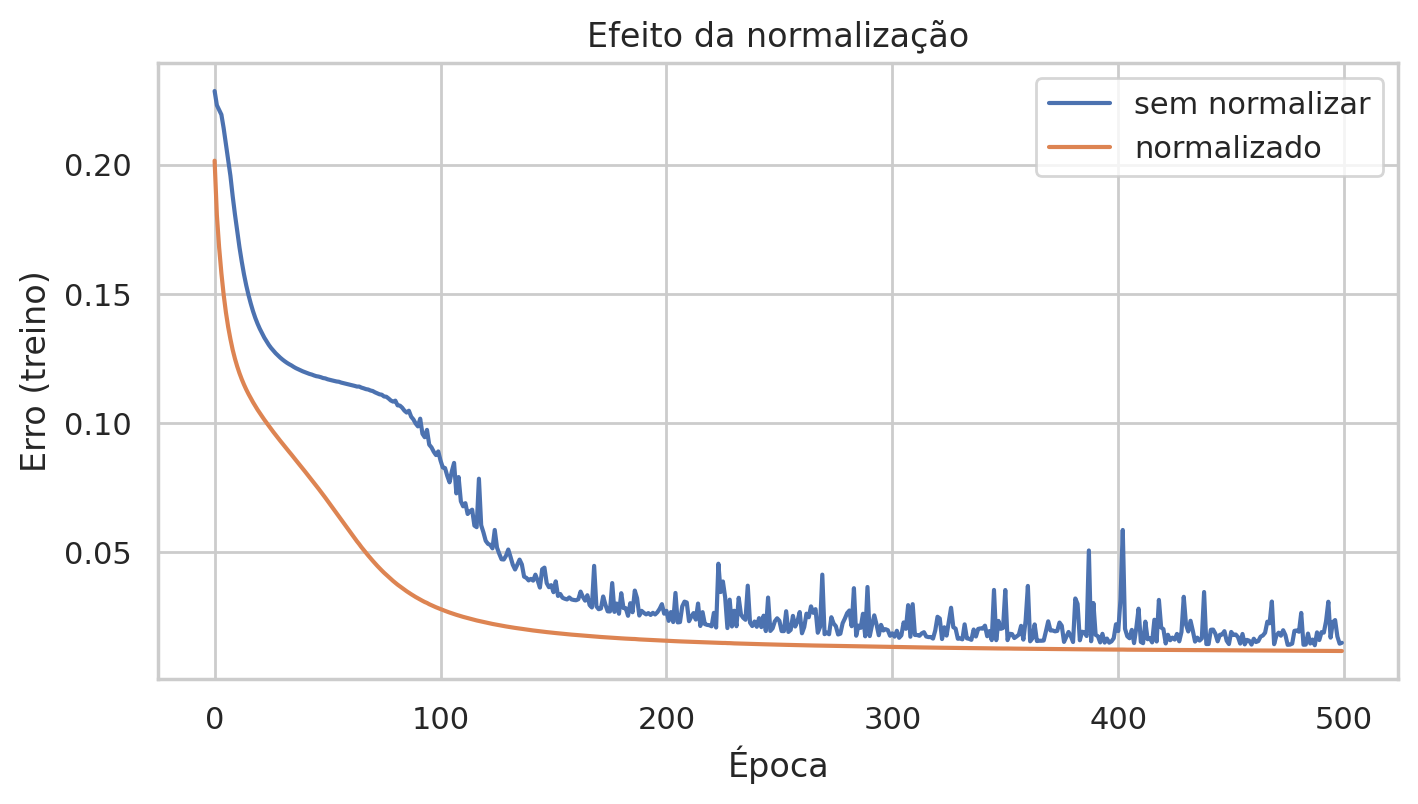

In [28]:
sem_norm = MLP(n_oculta=5, taxa=0.05, seed=0).fit(X_treino, y_treino, 500, X_teste, y_teste)
com_norm = MLP(n_oculta=5, taxa=0.05, seed=0).fit(X_treino_n, y_treino, 500, X_teste_n, y_teste)

plt.figure(figsize=(8, 4))
plt.plot(sem_norm.historico["erro_treino"], label="sem normalizar")
plt.plot(com_norm.historico["erro_treino"], label="normalizado")
plt.xlabel("Época")
plt.ylabel("Erro (treino)")
plt.title("Efeito da normalização")
plt.legend()
plt.show()

### Taxa de aprendizado
Taxa pequena converge devagar; taxa grande converge rápido mas pode oscilar.

Igual ao experimento de neurônios, rodamos cada taxa 5 vezes com outra separação treino/teste. A curva é a média das 5 e o número na legenda é a acurácia média no teste.

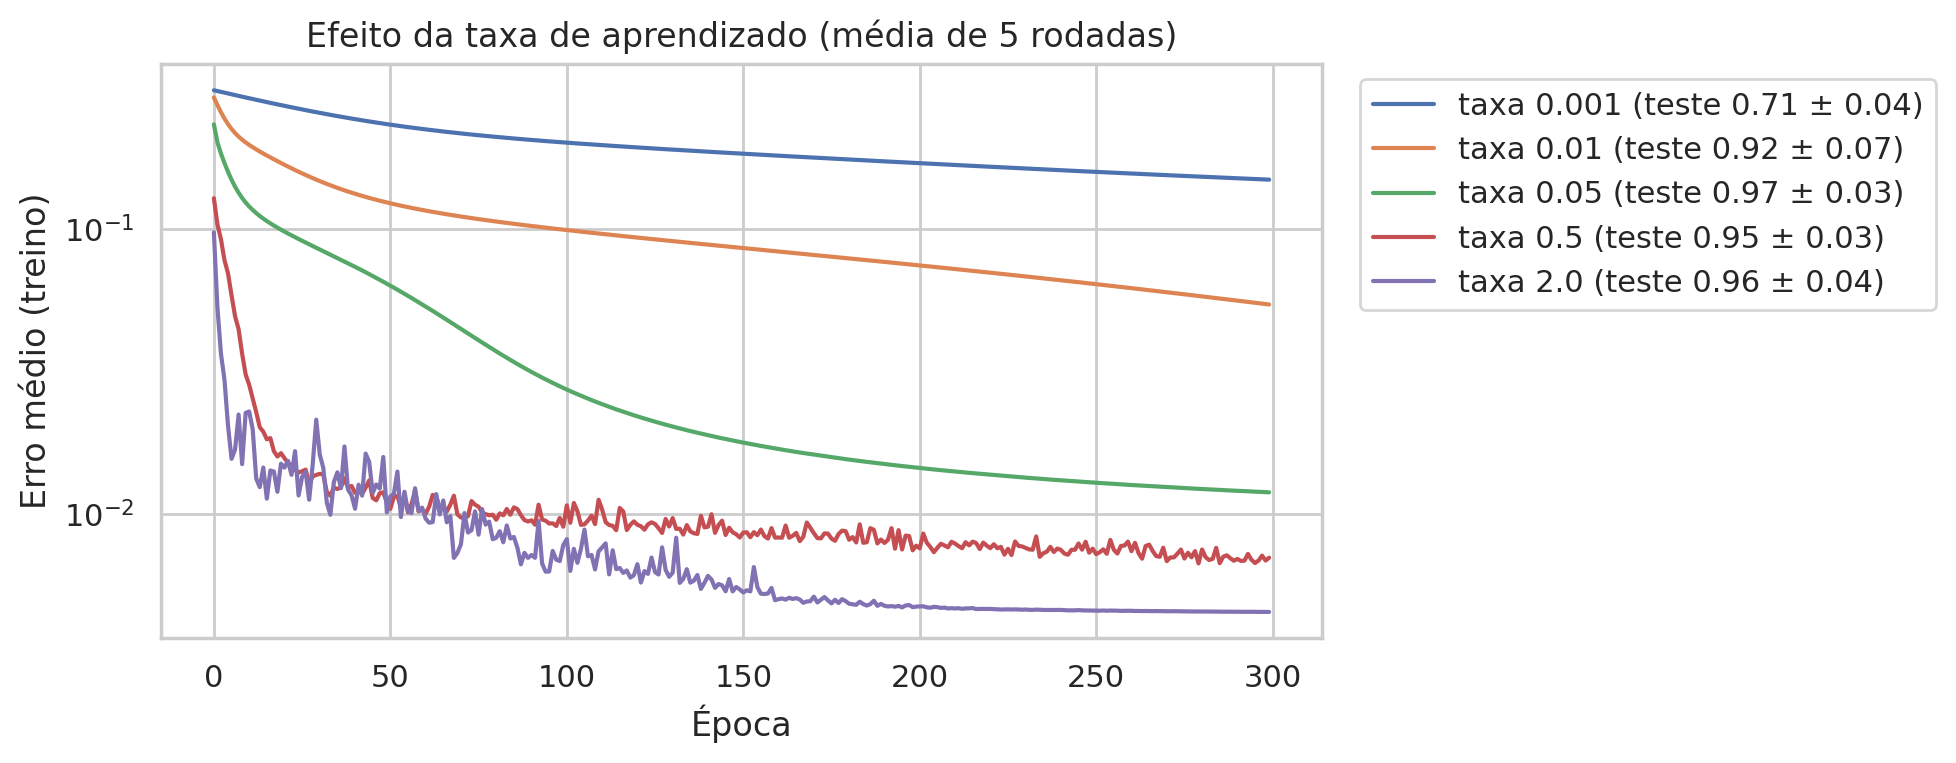

In [29]:
plt.figure(figsize=(10, 4))
for taxa in [0.001, 0.01, 0.05, 0.5, 2.0]:
    curvas, accs = [], []
    for seed in range(5):
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
        sc = StandardScaler().fit(Xa)
        m = MLP(n_oculta=5, taxa=taxa, seed=seed).fit(sc.transform(Xa), ya, 300, sc.transform(Xb), yb)
        curvas.append(m.historico["erro_treino"])
        accs.append(m.historico["acc_teste"].iloc[-1])
    plt.plot(np.mean(curvas, axis=0), label="taxa %s (teste %.2f ± %.2f)" % (taxa, np.mean(accs), np.std(accs)))
plt.xlabel("Época")
plt.ylabel("Erro médio (treino)")
plt.yscale("log")
plt.title("Efeito da taxa de aprendizado (média de 5 rodadas)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Número de neurônios e função de ativação
O resultado depende da inicialização aleatória e de quais flores caíram no teste (com 30 flores, cada erro vale 3,3%).
Então rodamos cada configuração 5 vezes, cada vez com outra seed **e outra separação treino/teste**, e olhamos a média e o desvio.

In [30]:
resultados = []
for ativacao in ["sigmoid", "tanh", "relu"]:
    for n_oculta in [1, 2, 3, 5, 10, 30]:
        accs = []
        for seed in range(5):
            Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
            sc = StandardScaler().fit(Xa)
            m = MLP(n_oculta=n_oculta, taxa=0.05 if ativacao == "sigmoid" else 0.01, ativacao=ativacao, seed=seed)
            m.fit(sc.transform(Xa), ya, 300)
            accs.append(np.mean(m.predict(sc.transform(Xb)) == yb))
        resultados.append({"ativacao": ativacao, "neuronios": n_oculta, "acc_media": np.mean(accs), "acc_desvio": np.std(accs)})
resultados = pd.DataFrame(resultados)
resultados.pivot(index="neuronios", columns="ativacao", values="acc_media").round(3)

ativacao,relu,sigmoid,tanh
neuronios,,,
1,0.867,0.933,0.900
2,0.960,0.973,0.973
3,0.953,0.967,0.960
5,0.967,0.973,0.960
10,0.960,0.973,0.953
30,0.940,0.967,0.947


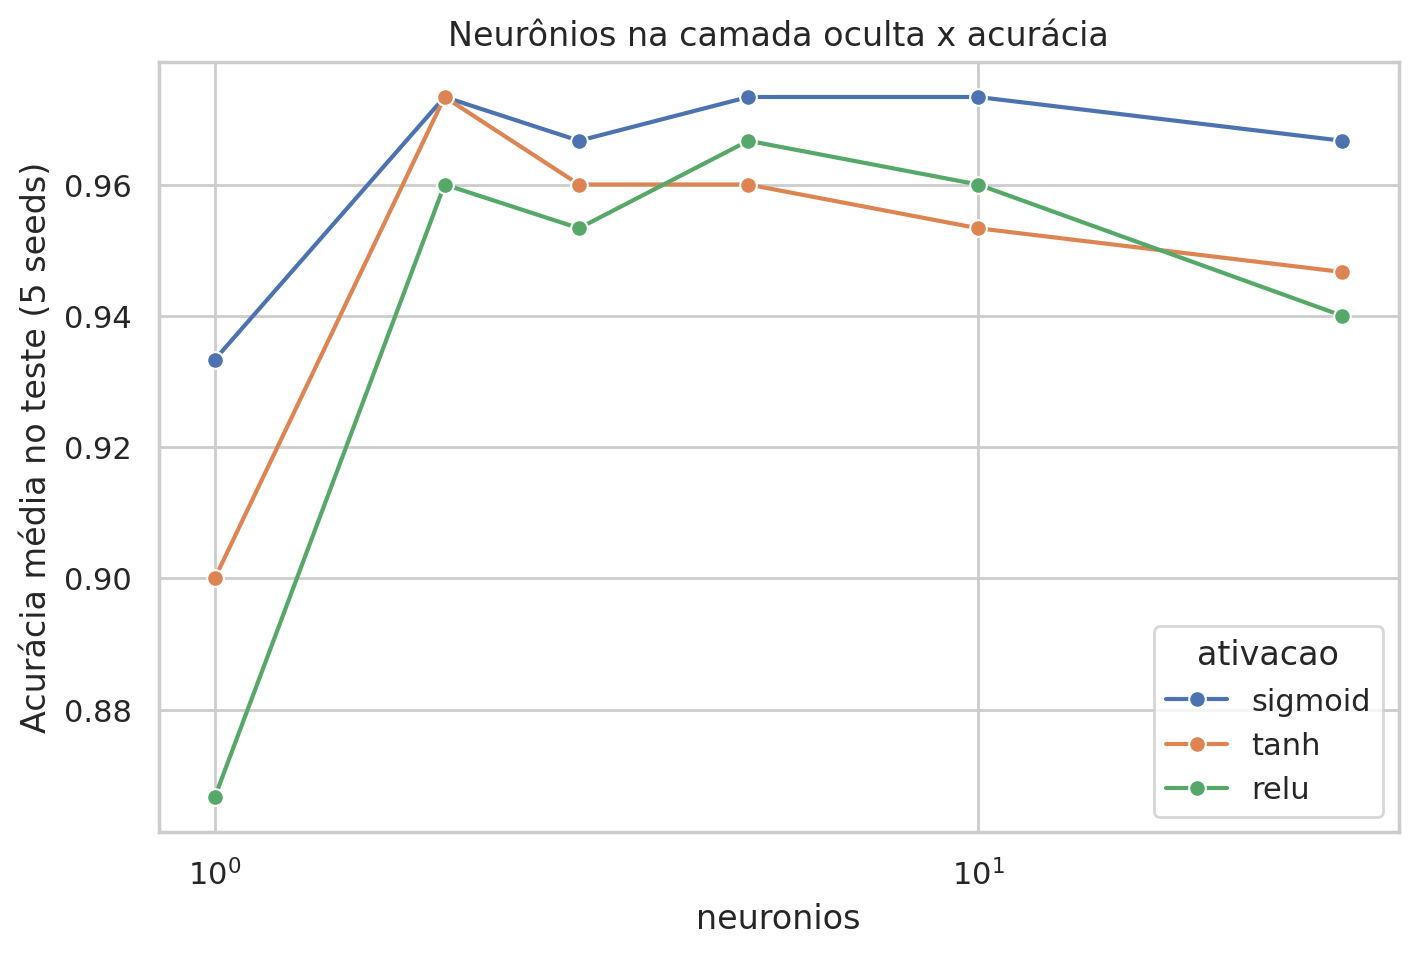

In [31]:
plt.figure(figsize=(8, 5))
sns.lineplot(data=resultados, x="neuronios", y="acc_media", hue="ativacao", marker="o")
plt.xscale("log")
plt.ylabel("Acurácia média no teste (5 seeds)")
plt.title("Neurônios na camada oculta x acurácia")
plt.show()

### Overfitting
Nos experimentos de cima (300 a 500 épocas) o erro de teste acompanha o de treino, não parece ter overfitting. Pra ver se ele aparece depois, treinamos a mesma rede (5 neurônios, taxa 0.05) por 5000 épocas, em 5 separações treino/teste:

In [32]:
overfit = []
historicos = []
for seed in range(5):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    sc = StandardScaler().fit(Xa)
    m = MLP(n_oculta=5, taxa=0.05, seed=seed).fit(sc.transform(Xa), ya, 5000, sc.transform(Xb), yb)
    h = m.historico
    historicos.append(h)
    melhor = h["erro_teste"].idxmin()
    overfit.append({"rodada": seed, "epoca_menor_erro": h["epoca"][melhor],
                    "erro_teste_minimo": h["erro_teste"][melhor], "erro_teste_final": h["erro_teste"].iloc[-1],
                    "acc_teste_no_minimo": h["acc_teste"][melhor], "acc_teste_final": h["acc_teste"].iloc[-1]})
overfit = pd.DataFrame(overfit)
overfit.round(4)

,rodada,epoca_menor_erro,erro_teste_minimo,erro_teste_final,acc_teste_no_minimo,acc_teste_final
0,0,434,0.0066,0.0435,1.0000,0.9333
1,1,4932,0.0025,0.0027,1.0000,1.0000
2,2,568,0.0070,0.0160,1.0000,0.9667
3,3,766,0.0237,0.0441,0.9333,0.9333
4,4,181,0.0261,0.0435,0.9333,0.9333


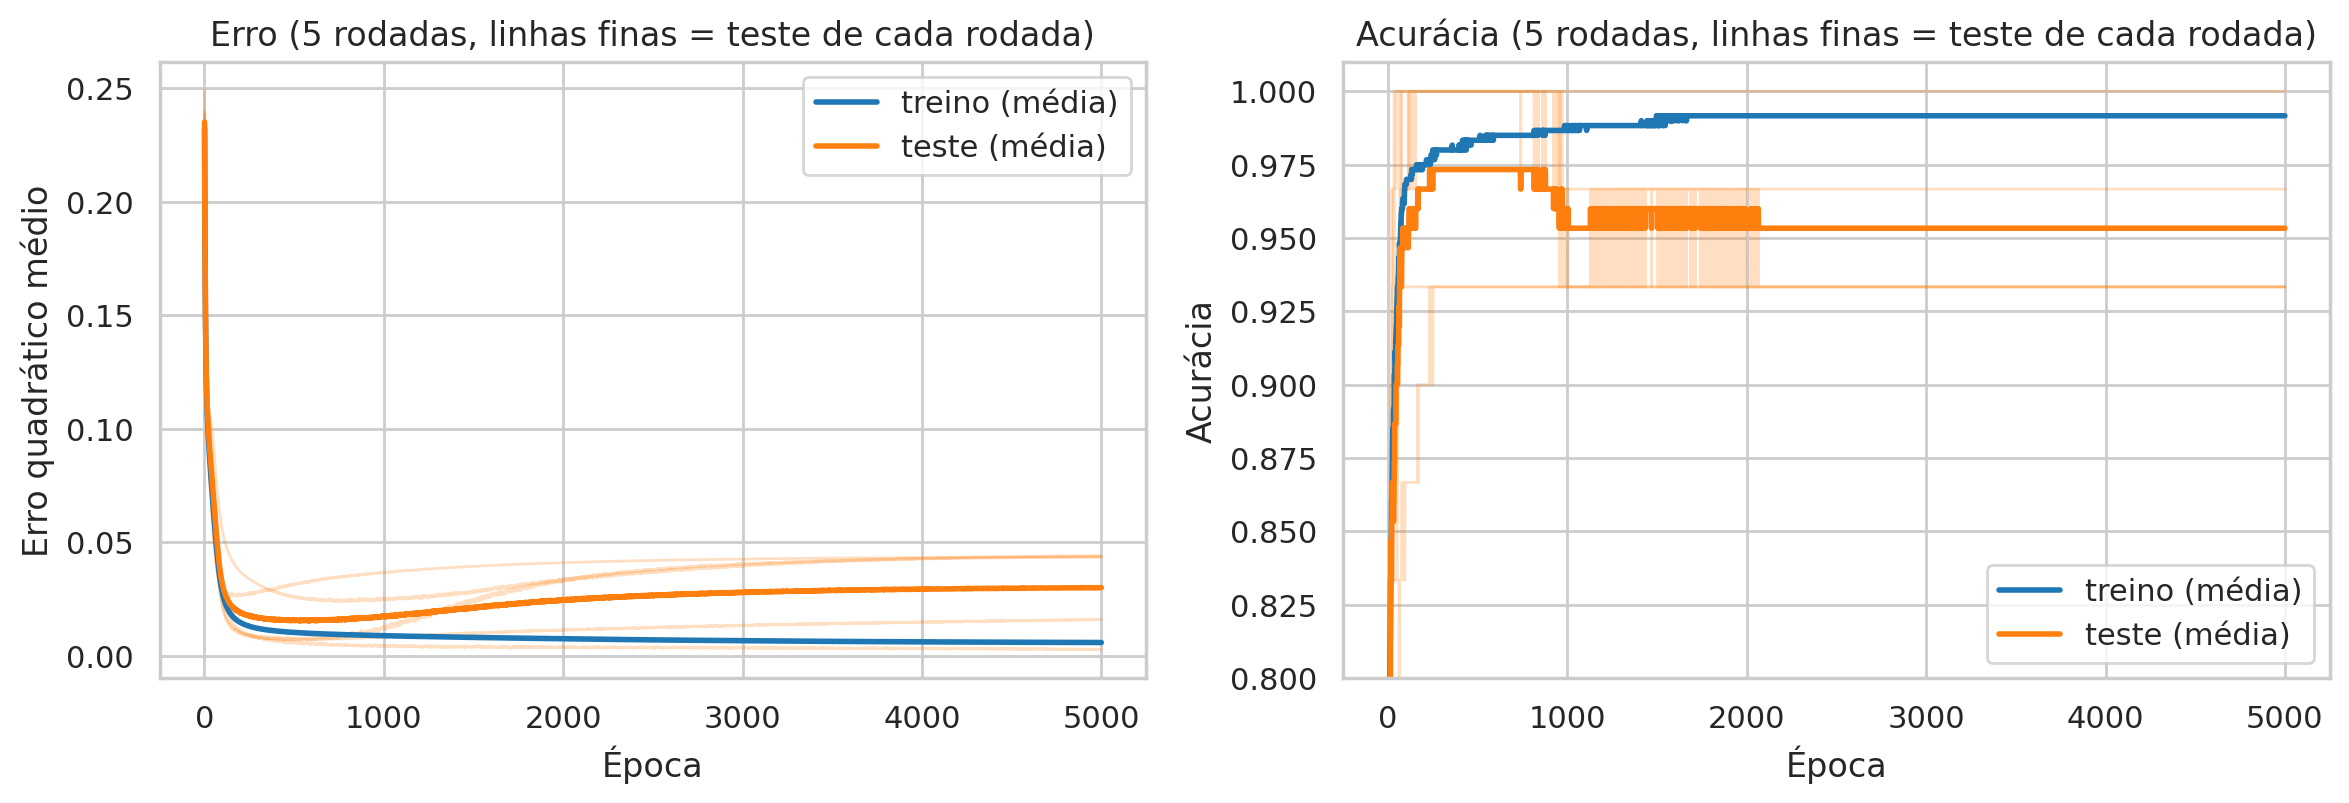

In [33]:
plt.figure(figsize=(14, 4))
for coluna, n in [("erro", 1), ("acc", 2)]:
    plt.subplot(1, 2, n)
    for h in historicos:
        plt.plot(h["epoca"], h[coluna + "_teste"], color="tab:orange", alpha=0.25, linewidth=1)
    plt.plot(historicos[0]["epoca"], np.mean([h[coluna + "_treino"] for h in historicos], axis=0), color="tab:blue", linewidth=2, label="treino (média)")
    plt.plot(historicos[0]["epoca"], np.mean([h[coluna + "_teste"] for h in historicos], axis=0), color="tab:orange", linewidth=2, label="teste (média)")
    plt.xlabel("Época")
    plt.legend()
plt.subplot(1, 2, 1)
plt.ylabel("Erro quadrático médio")
plt.title("Erro (5 rodadas, linhas finas = teste de cada rodada)")
plt.subplot(1, 2, 2)
plt.ylabel("Acurácia")
plt.ylim(0.8, 1.01)
plt.title("Acurácia (5 rodadas, linhas finas = teste de cada rodada)")
plt.show()

In [34]:
overfit[["acc_teste_no_minimo", "acc_teste_final"]].mean().round(3)

acc_teste_no_minimo    0.973
acc_teste_final        0.953
dtype: float64

Em 4 das 5 rodadas o erro de teste chega no mínimo entre as épocas ~180 e ~770 e depois sobe devagar, enquanto o de treino continua caindo. Mas na acurácia quase não aparece: na média vai de 0.973 pra 0.953 (1 ou 2 flores a mais erradas em 2 rodadas).

Ou seja, tem um overfitting bem leve só com muitas épocas. O Iris é fácil e a rede é pequena, não tem muito o que decorar.